In [1]:
from google.colab import files
uploads=files.upload()

Saving X_train.pkl to X_train.pkl
Saving X_test.pkl to X_test.pkl
Saving X_valid.pkl to X_valid.pkl
Saving y_train.pkl to y_train.pkl
Saving y_test.pkl to y_test.pkl
Saving y_valid.pkl to y_valid.pkl
Saving id_to_word.pkl to id_to_word.pkl
Saving word_to_id.pkl to word_to_id.pkl


In [2]:
import pickle

with open("/content/X_train.pkl", "rb") as f:
    X_train = pickle.load(f)

with open("/content/y_train.pkl", "rb") as f:
    y_train = pickle.load(f)

with open("/content/X_valid.pkl", "rb") as f:
    X_valid = pickle.load(f)

with open("/content/y_valid.pkl", "rb") as f:
    y_valid = pickle.load(f)

with open("/content/X_test.pkl", "rb") as f:
    X_test = pickle.load(f)

with open("/content/y_test.pkl", "rb") as f:
    y_test = pickle.load(f)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_valid:", X_valid.shape)
print("y_valid:", y_valid.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (1799608, 10)
y_train: (1799608,)
X_valid: (187479, 10)
y_valid: (187479,)
X_test: (210514, 10)
y_test: (210514,)


In [3]:
with open ("/content/word_to_id.pkl", "rb") as f:
  word_to_id = pickle.load(f)

In [4]:
vocab_size=len(word_to_id)
print(vocab_size)

84352


In [5]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPUs:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [6]:
!nvidia-smi

Sun Aug 16 16:40:04 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   33C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([Embedding(input_dim=vocab_size,output_dim=128),
    LSTM(128),
    Dropout(0.2),
    Dense(128,activation="relu"),
    Dense(vocab_size,activation="softmax")
])

In [ ]:
model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "/content/best_next_word_lstm.keras",
    monitor="val_loss",
    save_best_only=True,
    mode="min"
)

In [ ]:
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_valid, y_valid),
    epochs=10,
    batch_size=128,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 560s 39ms/step - accuracy: 0.1489 - loss: 6.7242 - val_accuracy: 0.1825 - val_loss: 6.4923
Epoch 2/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 553s 39ms/step - accuracy: 0.1885 - loss: 6.0176 - val_accuracy: 0.1923 - val_loss: 6.3562
Epoch 3/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 558s 40ms/step - accuracy: 0.2044 - loss: 5.7101 - val_accuracy: 0.1970 - val_loss: 6.2993
Epoch 4/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 556s 39ms/step - accuracy: 0.2168 - loss: 5.4882 - val_accuracy: 0.1978 - val_loss: 6.3135
Epoch 5/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 548s 39ms/step - accuracy: 0.2279 - loss: 5.3064 - val_accuracy: 0.1992 - val_loss: 6.3680


In [ ]:
model.save("/content/next_word_lstm1.keras")

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model1 = Sequential([Embedding(input_dim=vocab_size,output_dim=128),
    LSTM(128),
    Dropout(0.2),
    Dense(128,activation="relu"),
    Dense(vocab_size,activation="softmax")
])

In [ ]:
model1.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [ ]:
model1.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model1.fit(
    X_train,
    y_train,
    validation_data=(X_valid, y_valid),
    epochs=5,
    batch_size=128
)

NameError: name 'model1' is not defined

In [ ]:
model.save("/content/next_word_lstm2.keras")

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/best_next_word_lstm.keras")

In [ ]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    batch_size=128
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

1645/1645 ━━━━━━━━━━━━━━━━━━━━ 45s 27ms/step - accuracy: 0.1952 - loss: 6.3380
Test Loss: 6.3380303382873535
Test Accuracy: 0.19520317018032074


In [ ]:
import tensorflow as tf

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="top_1_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top_5_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=10,
            name="top_10_accuracy"
        )
    ]
)

results = model.evaluate(
    X_test,
    y_test,
    batch_size=128,
    return_dict=True
)

for name, value in results.items():
    print(f"{name}: {value:.4f}")

1645/1645 ━━━━━━━━━━━━━━━━━━━━ 49s 30ms/step - loss: 6.3380 - top_10_accuracy: 0.4286 - top_1_accuracy: 0.1952 - top_5_accuracy: 0.3632
loss: 6.3380
top_10_accuracy: 0.4286
top_1_accuracy: 0.1952
top_5_accuracy: 0.3632


In [ ]:
print(model.name)
model.summary()

sequential


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 128)        │    10,797,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84352)          │    10,881,408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,826,560 (83.26 MB)

 Trainable params: 21,826,560 (83.26 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("Vocabulary size:", vocab_size)

print("y_test min:", y_test.min())
print("y_test max:", y_test.max())

print("Model output:", model.output_shape)

X_test shape: (210514, 10)
y_test shape: (210514,)
Vocabulary size: 84352
y_test min: 1
y_test max: 84341
Model output: (None, 84352)


In [7]:
with open ("/content/id_to_word.pkl", "rb") as f:
  id_to_word = pickle.load(f)
with open ("/content/word_to_id.pkl", "rb") as f:
  word_to_id = pickle.load(f)


In [8]:
idx2word = {idx: word for word, idx in word_to_id.items()}

print(list(idx2word.items())[:10])

[(0, '<PAD>'), (1, '<UNK>'), (2, 'Senjō'), (3, 'no'), (4, 'Valkyria'), (5, '3'), (6, ':'), (7, 'Unrecorded'), (8, 'Chronicles'), (9, '(')]


In [ ]:
import numpy as np

def predict_next_words(text, model, word_to_id, id_to_word, top_k=10):
    words = text.lower().split()

    input_ids = [
        word_to_id.get(word, word_to_id.get("<UNK>"))
        for word in words
    ]

    input_ids = input_ids[-10:]

    if len(input_ids) < 10:
        input_ids = [0] * (10 - len(input_ids)) + input_ids

    X = np.array([input_ids])

    probabilities = model.predict(X, verbose=0)[0]

    top_indices = np.argsort(probabilities)[-top_k:][::-1]

    results = []

    for idx in top_indices:
        word = id_to_word.get(idx, "<UNK>")
        probability = probabilities[idx]
        results.append((word, probability))

    return results

In [ ]:
context = "the capital of france is"

predictions = predict_next_words(
    context,
    model,
    word_to_id,
    id_to_word,
    top_k=10
)

for rank, (word, probability) in enumerate(predictions, 1):
    print(f"{rank}. {word:<20} {probability:.4f}")

1. the                  0.0741
2. a                    0.0612
3. an                   0.0118
4. also                 0.0110
5. not                  0.0101
6. used                 0.0094
7. known                0.0081
8. one                  0.0074
9. located              0.0059
10. to                   0.0059


In [ ]:
contexts = [
    "the capital of france is",
    "the president of the",
    "he was born in",
    "the first world war",
    "the united states",
    "one of the most",
    "the city of new",
    "according to the"
]

for context in contexts:
    print("\nContext:", context)

    predictions = predict_next_words(
        context,
        model,
        word_to_id,
        id_to_word,
        top_k=5
    )

    for rank, (word, probability) in enumerate(predictions, 1):
        print(f"{rank}. {word} ({probability:.4f})")


Context: the capital of france is
1. the (0.0741)
2. a (0.0612)
3. an (0.0118)
4. also (0.0110)
5. not (0.0101)

Context: the president of the
1. `` (0.0060)
2. two (0.0049)
3. first (0.0046)
4. city (0.0035)
5. same (0.0034)

Context: he was born in
1. the (0.1740)
2. a (0.0355)
3. his (0.0106)
4. an (0.0100)
5. which (0.0093)

Context: the first world war
1. . (0.3137)
2. , (0.1741)
3. in (0.0496)
4. and (0.0396)
5. of (0.0185)

Context: the united states
1. of (0.2029)
2. . (0.1419)
3. that (0.1393)
4. , (0.1195)
5. in (0.0408)

Context: one of the most
1. important (0.0200)
2. of (0.0133)
3. common (0.0104)
4. successful (0.0091)
5. popular (0.0087)

Context: the city of new
1. , (0.0120)
2. and (0.0115)
3. . (0.0069)
4. of (0.0040)
5. to (0.0029)

Context: according to the
1. `` (0.0085)
2. first (0.0040)
3. two (0.0034)
4. same (0.0033)
5. most (0.0033)


In [ ]:
import numpy as np

def show_test_predictions(X_test, y_test, model, idx2word, n=10, top_k=5):
    indices = np.random.choice(len(X_test), n, replace=False)

    for i in indices:
        x = X_test[i]
        actual_id = y_test[i]

        probabilities = model.predict(
            np.array([x]),
            verbose=0
        )[0]

        top_indices = np.argsort(probabilities)[-top_k:][::-1]

        context = " ".join(
            idx2word.get(int(token), "<UNK>")
            for token in x
        )

        actual_word = idx2word.get(
            int(actual_id),
            "<UNK>"
        )

        predictions = [
            idx2word.get(int(idx), "<UNK>")
            for idx in top_indices
        ]

        print("Context:", context)
        print("Actual:", actual_word)
        print("Predicted:", predictions)
        print("-" * 70)

In [ ]:
show_test_predictions(
    X_test,
    y_test,
    model,
    idx2word,
    n=10,
    top_k=5
)

Context: their lives ; ribs that do not connect at the
Actual: underside
Predicted: ['same', 'time', 'end', 'city', 'United']
----------------------------------------------------------------------
Context: in 733 , <UNK> 's period as archbishop appears to
Actual: have
Predicted: ['be', 'have', 'the', 'make', 'take']
----------------------------------------------------------------------
Context: The skull morphology of some small <UNK> has been compared
Actual: to
Predicted: ['to', 'by', 'with', 'in', 'for']
----------------------------------------------------------------------
Context: for photographs of graves from relatives of deceased soldiers .
Actual: By
Predicted: ['The', 'In', 'It', 'He', 'This']
----------------------------------------------------------------------
Context: The forehead is wrinkled in a frown . The lips
Actual: are
Predicted: ['of', ',', 'and', 'is', 'was']
----------------------------------------------------------------------
Context: Science High School , the

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

model_v2 = Sequential([
    Input(shape=(X_train.shape[1],)),

    Embedding(
        input_dim=vocab_size,
        output_dim=256
    ),

    LSTM(
        256,
        return_sequences=True
    ),

    Dropout(0.3),

    LSTM(
        128
    ),

    Dropout(0.3),

    Dense(
        256,
        activation="relu"
    ),

    Dropout(0.2),

    Dense(
        vocab_size,
        activation="softmax"
    )
])

model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(name="top_1_accuracy"),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top_5_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=10,
            name="top_10_accuracy"
        )
    ]
)

model_v2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 256)        │    21,594,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 10, 256)        │       525,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 256)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       197,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84352)          │    21,678,464 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,028,032 (167.95 MB)

 Trainable params: 44,028,032 (167.95 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    mode="min",
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "/content/best_next_word_lstm_v2.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True
)

In [ ]:
history_v2 = model_v2.fit(
    X_train,
    y_train,
    validation_data=(X_valid, y_valid),
    epochs=10,
    batch_size=128,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 857s 60ms/step - loss: 6.8889 - top_10_accuracy: 0.3484 - top_1_accuracy: 0.1314 - top_5_accuracy: 0.2803 - val_loss: 6.6356 - val_top_10_accuracy: 0.3799 - val_top_1_accuracy: 0.1664 - val_top_5_accuracy: 0.3195
Epoch 2/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 838s 60ms/step - loss: 6.3288 - top_10_accuracy: 0.3906 - top_1_accuracy: 0.1677 - top_5_accuracy: 0.3247 - val_loss: 6.4955 - val_top_10_accuracy: 0.3963 - val_top_1_accuracy: 0.1810 - val_top_5_accuracy: 0.3347
Epoch 3/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 859s 59ms/step - loss: 6.1162 - top_10_accuracy: 0.4053 - top_1_accuracy: 0.1805 - top_5_accuracy: 0.3400 - val_loss: 6.4263 - val_top_10_accuracy: 0.4069 - val_top_1_accuracy: 0.1866 - val_top_5_accuracy: 0.3437
Epoch 4/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 826s 59ms/step - loss: 5.9714 - top_10_accuracy: 0.4157 - top_1_accuracy: 0.1889 - top_5_accuracy: 0.3500 - val_loss: 6.3861 - val_top_10_accuracy: 0.4138 - val_top_1_accuracy: 0.1909 -

In [ ]:
from tensorflow.keras.models import load_model

best_model_v2 = load_model(
    "/content/best_next_word_lstm_v2.keras"
)

In [ ]:
import tensorflow as tf

best_model_v2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="top_1_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top_5_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=10,
            name="top_10_accuracy"
        )
    ]
)

In [ ]:
results_v2 = best_model_v2.evaluate(
    X_test,
    y_test,
    batch_size=128,
    return_dict=True
)

print(f"Test Loss: {results_v2['loss']:.4f}")
print(f"Top-1 Accuracy: {results_v2['top_1_accuracy'] * 100:.2f}%")
print(f"Top-5 Accuracy: {results_v2['top_5_accuracy'] * 100:.2f}%")
print(f"Top-10 Accuracy: {results_v2['top_10_accuracy'] * 100:.2f}%")

1645/1645 ━━━━━━━━━━━━━━━━━━━━ 50s 30ms/step - loss: 6.4173 - top_10_accuracy: 0.4205 - top_1_accuracy: 0.1903 - top_5_accuracy: 0.3547
Test Loss: 6.4173
Top-1 Accuracy: 19.03%
Top-5 Accuracy: 35.47%
Top-10 Accuracy: 42.05%


In [ ]:
model_v2.save("/content/next_word_lstmv2.keras")

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("/content/best_next_word_lstm_v2.keras")

In [ ]:
results = model.evaluate(
    X_test,
    y_test,
    batch_size=128,
    return_dict=True
)

print(f"Test Loss: {results['loss']:.4f}")
print(f"Top-1 Accuracy: {results['top_1_accuracy'] * 100:.2f}%")
print(f"Top-5 Accuracy: {results['top_5_accuracy'] * 100:.2f}%")
print(f"Top-10 Accuracy: {results['top_10_accuracy'] * 100:.2f}%")

1645/1645 ━━━━━━━━━━━━━━━━━━━━ 51s 31ms/step - loss: 6.4173 - top_10_accuracy: 0.4205 - top_1_accuracy: 0.1903 - top_5_accuracy: 0.3547
Test Loss: 6.4173
Top-1 Accuracy: 19.03%
Top-5 Accuracy: 35.47%
Top-10 Accuracy: 42.05%


In [ ]:
import tensorflow as tf

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="top_1_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top_5_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=10,
            name="top_10_accuracy"
        )
    ]
)

results = model.evaluate(
    X_test,
    y_test,
    batch_size=128,
    return_dict=True
)

for name, value in results.items():
    print(f"{name}: {value:.4f}")

1645/1645 ━━━━━━━━━━━━━━━━━━━━ 53s 32ms/step - loss: 6.4173 - top_10_accuracy: 0.4205 - top_1_accuracy: 0.1903 - top_5_accuracy: 0.3547
loss: 6.4173
top_10_accuracy: 0.4205
top_1_accuracy: 0.1903
top_5_accuracy: 0.3547


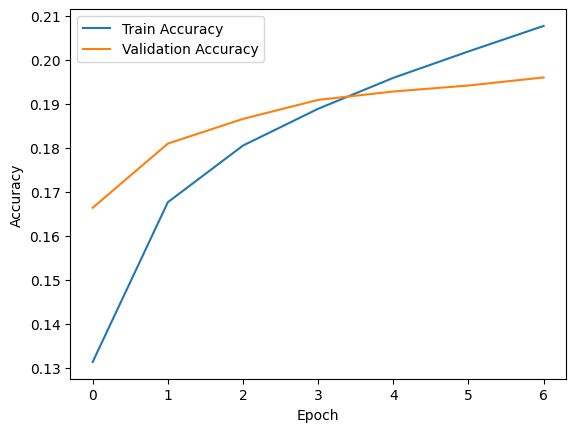

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history_v2.history["top_1_accuracy"], label="Train Accuracy")
plt.plot(history_v2.history["val_top_1_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

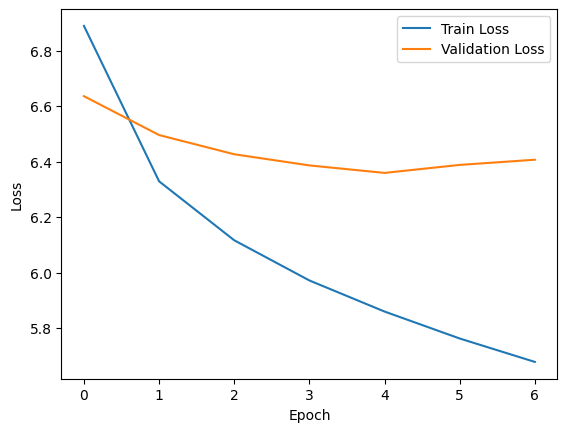

In [ ]:
plt.plot(history_v2.history["loss"], label="Train Loss")
plt.plot(history_v2.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [ ]:
print(history_v2.history)

{'loss': [6.888856410980225, 6.328771114349365, 6.116243839263916, 5.971418380737305, 5.859445571899414, 5.762278079986572, 5.677878379821777], 'top_10_accuracy': [0.3483797609806061, 0.3906378448009491, 0.4053310453891754, 0.41571274399757385, 0.4240906834602356, 0.43101775646209717, 0.4372313320636749], 'top_1_accuracy': [0.1313675045967102, 0.1676642894744873, 0.18053987622261047, 0.18889613449573517, 0.19592544436454773, 0.2019273042678833, 0.20772691071033478], 'top_5_accuracy': [0.28027769923210144, 0.3247146010398865, 0.3400101661682129, 0.35001957416534424, 0.35817021131515503, 0.3650650680065155, 0.3715631365776062], 'val_loss': [6.635645389556885, 6.495548725128174, 6.426307678222656, 6.386118412017822, 6.359095573425293, 6.387929916381836, 6.40664005279541], 'val_top_10_accuracy': [0.3799252212047577, 0.3962737023830414, 0.40692025423049927, 0.41380101442337036, 0.41802549362182617, 0.4208737909793854, 0.4227193593978882], 'val_top_1_accuracy': [0.1664026379585266, 0.1809855

In [9]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

model_v3 = Sequential([
    Input(shape=(X_train.shape[1],)),
    Embedding(
        input_dim=vocab_size,
        output_dim=128
    ),
    LSTM(128),
    Dropout(0.2),
    Dense(128, activation="relu"),
    Dense(vocab_size, activation="softmax")
])

model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="top_1_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top_5_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=10,
            name="top_10_accuracy"
        )
    ]
)

model_v3.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 10, 128)        │    10,797,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84352)          │    10,881,408 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,826,560 (83.26 MB)

 Trainable params: 21,826,560 (83.26 MB)

 Non-trainable params: 0 (0.00 B)

In [10]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    mode="min",
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "/content/best_next_word_lstm_v3.keras",
    monitor="val_loss",
    mode="min",
    save_best_only=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=1e-5,
    mode="min",
    verbose=1
)

In [11]:
history_v3 = model_v3.fit(
    X_train,
    y_train,
    validation_data=(X_valid, y_valid),
    epochs=10,
    batch_size=128,
    callbacks=[
        early_stopping,
        checkpoint,
        reduce_lr
    ]
)

Epoch 1/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 587s 41ms/step - loss: 6.7336 - top_10_accuracy: 0.3668 - top_1_accuracy: 0.1485 - top_5_accuracy: 0.3010 - val_loss: 6.4910 - val_top_10_accuracy: 0.3975 - val_top_1_accuracy: 0.1818 - val_top_5_accuracy: 0.3357 - learning_rate: 0.0010
Epoch 2/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 584s 42ms/step - loss: 6.0194 - top_10_accuracy: 0.4160 - top_1_accuracy: 0.1881 - top_5_accuracy: 0.3509 - val_loss: 6.3690 - val_top_10_accuracy: 0.4156 - val_top_1_accuracy: 0.1918 - val_top_5_accuracy: 0.3512 - learning_rate: 0.0010
Epoch 3/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 588s 42ms/step - loss: 5.7143 - top_10_accuracy: 0.4355 - top_1_accuracy: 0.2034 - top_5_accuracy: 0.3701 - val_loss: 6.3102 - val_top_10_accuracy: 0.4244 - val_top_1_accuracy: 0.1968 - val_top_5_accuracy: 0.3592 - learning_rate: 0.0010
Epoch 4/10
14060/14060 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - loss: 5.4632 - top_10_accuracy: 0.4499 - top_1_accuracy: 0.2177 - top_5_accuracy: 0.3848
Epoch 4: 

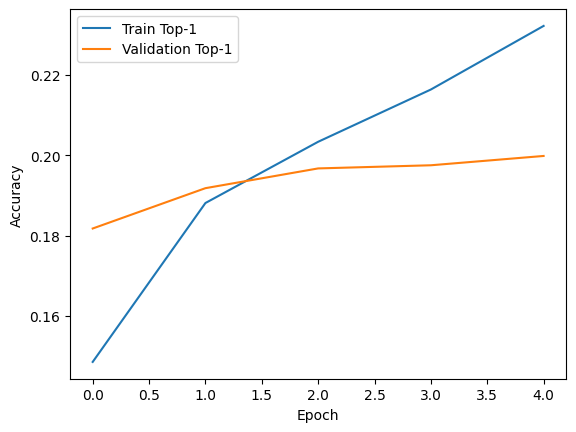

In [12]:
import matplotlib.pyplot as plt

plt.plot(history_v3.history["top_1_accuracy"], label="Train Top-1")
plt.plot(history_v3.history["val_top_1_accuracy"], label="Validation Top-1")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

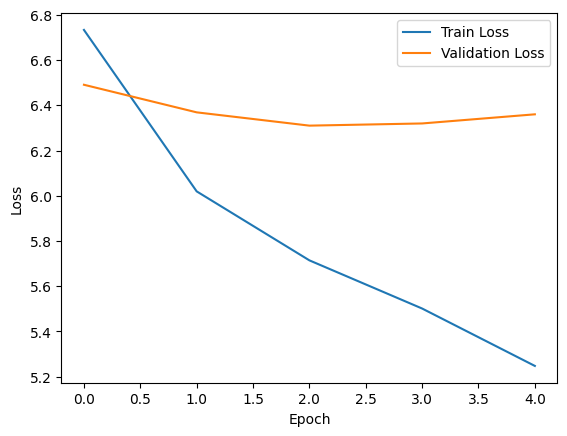

In [13]:
plt.plot(history_v3.history["loss"], label="Train Loss")
plt.plot(history_v3.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [14]:
print(history_v3.history)

{'loss': [6.733605861663818, 6.019448280334473, 5.714295387268066, 5.501224040985107, 5.247352123260498], 'top_10_accuracy': [0.3668215572834015, 0.4159705936908722, 0.43552374839782715, 0.4498290717601776, 0.46549859642982483], 'top_1_accuracy': [0.14853735268115997, 0.18813040852546692, 0.20339152216911316, 0.21641546487808228, 0.2322583645582199], 'top_5_accuracy': [0.30104222893714905, 0.3509197533130646, 0.3700866997241974, 0.3844459354877472, 0.4004955589771271], 'val_loss': [6.491038799285889, 6.369009494781494, 6.310232639312744, 6.319868564605713, 6.3602776527404785], 'val_top_10_accuracy': [0.39754852652549744, 0.4155878722667694, 0.4243675172328949, 0.4290613830089569, 0.43088024854660034], 'val_top_1_accuracy': [0.1817803531885147, 0.19182948768138885, 0.19675269722938538, 0.19753679633140564, 0.19985705614089966], 'val_top_5_accuracy': [0.3357389271259308, 0.35120201110839844, 0.3591548800468445, 0.3628672957420349, 0.3657262921333313], 'learning_rate': [0.0010000000474974

In [15]:
from tensorflow.keras.models import load_model

best_model_v3 = load_model(
    "/content/best_next_word_lstm_v3.keras"
)

In [16]:
import tensorflow as tf

best_model_v3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=[
        tf.keras.metrics.SparseCategoricalAccuracy(
            name="top_1_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=5,
            name="top_5_accuracy"
        ),
        tf.keras.metrics.SparseTopKCategoricalAccuracy(
            k=10,
            name="top_10_accuracy"
        )
    ]
)

In [17]:
results_v3 = best_model_v3.evaluate(
    X_test,
    y_test,
    batch_size=128,
    return_dict=True
)

print(f"Test Loss: {results_v3['loss']:.4f}")
print(f"Top-1 Accuracy: {results_v3['top_1_accuracy'] * 100:.2f}%")
print(f"Top-5 Accuracy: {results_v3['top_5_accuracy'] * 100:.2f}%")
print(f"Top-10 Accuracy: {results_v3['top_10_accuracy'] * 100:.2f}%")

1645/1645 ━━━━━━━━━━━━━━━━━━━━ 50s 30ms/step - loss: 6.3537 - top_10_accuracy: 0.4268 - top_1_accuracy: 0.1955 - top_5_accuracy: 0.3619
Test Loss: 6.3537
Top-1 Accuracy: 19.55%
Top-5 Accuracy: 36.19%
Top-10 Accuracy: 42.68%
